<a href="https://colab.research.google.com/github/crowell97/ES5201/blob/main/ES5201_Lecture22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Earth's Normal Modes — A Companion Notebook

**EARTH 5201 — Introduction to Seismology**

**The Ohio State University**

**Companion notebook to Lecture 22 — The Earth's Normal Modes**

This notebook works through the quantitative threads from lecture, genuinely computed rather than taken on faith:

1. **Vector spherical harmonics** — computing the radial (R), spheroidal (S), and toroidal (T) vector basis functions directly from Y_l^m, and confirming they are mutually orthogonal on the sphere.
2. **Degeneracy and splitting** — building a synthetic, split multiplet for a given (n, l) and recovering the splitting parameter by fitting the five peaks, the same way a seismologist would from a real spectrum.
3. **A worked check on named modes** — converting the lecture's stated periods for the breathing mode (0S0) and the football mode (0S2) into frequencies, exactly as in the deck.
4. **Normal modes and synthetic seismograms** — reproducing the lecture's mode-summation seismogram, and exploring how the quality factor Q controls the decay envelope.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pylab as plt
from scipy.special import sph_harm_y
from scipy.optimize import curve_fit

plt.rcParams["figure.figsize"] = (9, 5)

NAVY = "#1B2A44"
SLATE = "#3D4A5C"
SLATE_L = "#6E7A8A"
GOLD = "#B08D3F"
RETRO = "#8E3B46"


## Part 1 — Vector Spherical Harmonics

Lecture introduced three vector spherical harmonics built from the scalar Y_l^m, needed because displacement is a vector quantity:

$$R_l^m = Y_l^m\,\hat{\mathbf r}, \qquad
S_l^m = \frac{1}{\sqrt{l(l+1)}}\left[\frac{\partial Y_l^m}{\partial\theta}\hat{\boldsymbol\theta} + \frac{1}{\sin\theta}\frac{\partial Y_l^m}{\partial\phi}\hat{\boldsymbol\phi}\right], \qquad
T_l^m = \frac{1}{\sqrt{l(l+1)}}\left[\frac{1}{\sin\theta}\frac{\partial Y_l^m}{\partial\phi}\hat{\boldsymbol\theta} - \frac{\partial Y_l^m}{\partial\theta}\hat{\boldsymbol\phi}\right]$$

$R$ is purely radial (spheroidal motion's radial part); $S$ is tangential and curl-free on the sphere (the rest of spheroidal motion); $T$ is tangential and divergence-free on the sphere (toroidal motion). We compute $\partial Y_l^m/\partial\theta$ and $\partial Y_l^m/\partial\phi$ by finite differences directly on `sph_harm_y`, rather than looking up a derivative identity.

In [2]:
def Y(l, m, theta, phi):
    return sph_harm_y(l, m, theta, phi)

def dY_dtheta(l, m, theta, phi, h=1e-5):
    return (Y(l, m, theta + h, phi) - Y(l, m, theta - h, phi)) / (2 * h)

def dY_dphi(l, m, theta, phi, h=1e-5):
    return (Y(l, m, theta, phi + h) - Y(l, m, theta, phi - h)) / (2 * h)

def vector_harmonics(l, m, theta, phi):
    """Returns R, S, T as (r, theta, phi)-component triples at each grid point."""
    Yv = Y(l, m, theta, phi)
    R = (Yv, np.zeros_like(Yv), np.zeros_like(Yv))
    if l == 0:
        # S and T are undefined (0/0) for l=0 -- there is no tangential motion
        zero = np.zeros_like(Yv)
        return R, (zero, zero, zero), (zero, zero, zero)
    norm = np.sqrt(l * (l + 1))
    dYt = dY_dtheta(l, m, theta, phi)
    dYp = dY_dphi(l, m, theta, phi)
    S = (np.zeros_like(Yv), dYt / norm, (dYp / np.sin(theta)) / norm)
    T = (np.zeros_like(Yv), (dYp / np.sin(theta)) / norm, -dYt / norm)
    return R, S, T


### Confirming R, S, T are mutually orthogonal

$R_l^m$ is purely radial while $S_l^m$ and $T_l^m$ are purely tangential, so $R$ is trivially, pointwise orthogonal to both $S$ and $T$ at every point on the sphere -- they simply have no components in common. $S$ and $T$ are a different story: as complex-valued fields they are **not** pointwise orthogonal (their Hermitian dot product $S\cdot T^*$ is generally a nonzero, purely imaginary number at a given point), but they *are* orthogonal in the sense that actually matters for building a complete basis -- their surface integral over the sphere vanishes, exactly like the scalar harmonics $Y_l^m$. We check both properties below, including surface integrals for $R\cdot R^*$, $S\cdot S^*$, $T\cdot T^*$ (all equal to 1) and every cross term (all zero).

In [3]:
n_theta, n_phi = 140, 280
theta = np.linspace(1e-3, np.pi - 1e-3, n_theta)   # avoid the poles (S, T singular there)
phi = np.linspace(0, 2 * np.pi, n_phi)
THETA, PHI = np.meshgrid(theta, phi, indexing="ij")

l, m = 2, 1
R, S, T = vector_harmonics(l, m, THETA, PHI)

def dot(A, B):
    return A[0] * np.conj(B[0]) + A[1] * np.conj(B[1]) + A[2] * np.conj(B[2])

# R is purely radial; S and T are purely tangential -- so R.S* and R.T* are
# IDENTICALLY zero at every point, just from having no shared components.
rs = np.max(np.abs(dot(R, S)))
rt = np.max(np.abs(dot(R, T)))
print(f"max |R.S*| = {rs:.2e}  (R has no tangential component -- trivially zero)")
print(f"max |R.T*| = {rt:.2e}  (R has no tangential component -- trivially zero)")
assert rs < 1e-12 and rt < 1e-12

# S and T are NOT pointwise orthogonal as complex fields -- S.T* is a
# generally nonzero, purely imaginary number at a given point.
st = dot(S, T)
print(f"\nS.T* at a sample point: {st[70, 100]:.4f}  (nonzero, and essentially purely imaginary)")
print(f"max |Re(S.T*)| = {np.max(np.abs(np.real(st))):.2e}   max |Im(S.T*)| = {np.max(np.abs(np.imag(st))):.2e}")
print("\nR is pointwise orthogonal to S and T trivially (disjoint components).")
print("S and T are NOT pointwise orthogonal -- only in the surface-integral sense checked next.")

max |R.S*| = 0.00e+00  (R has no tangential component -- trivially zero)
max |R.T*| = 0.00e+00  (R has no tangential component -- trivially zero)

S.T* at a sample point: 0.0000-0.0022j  (nonzero, and essentially purely imaginary)
max |Re(S.T*)| = 0.00e+00   max |Im(S.T*)| = 1.99e-01

R is pointwise orthogonal to S and T trivially (disjoint components).
S and T are NOT pointwise orthogonal -- only in the surface-integral sense checked next.


In [4]:
def surface_integral(field_a, field_b):
    integrand = dot(field_a, field_b) * np.sin(THETA)
    return np.real(np.trapezoid(np.trapezoid(integrand, theta, axis=0), phi))

print("pair        integral     expected")
for name, (A, B) in {
    "<R,R>": (R, R), "<S,S>": (S, S), "<T,T>": (T, T),
    "<R,S>": (R, S), "<R,T>": (R, T), "<S,T>": (S, T),
}.items():
    val = surface_integral(A, B)
    expected = 1.0 if name in ("<R,R>", "<S,S>", "<T,T>") else 0.0
    print(f"{name:10s}  {val:9.4f}    {expected:9.4f}")

print("\nR, S, T are an orthonormal vector basis at each (l, m) -- the vector analogue of the")
print("orthonormal scalar harmonics Y_l^m, exactly as needed to represent any displacement field.")

pair        integral     expected
<R,R>          1.0000       1.0000
<S,S>          0.9999       1.0000
<T,T>          0.9999       1.0000
<R,S>          0.0000       0.0000
<R,T>          0.0000       0.0000
<S,T>          0.0000       0.0000

R, S, T are an orthonormal vector basis at each (l, m) -- the vector analogue of the
orthonormal scalar harmonics Y_l^m, exactly as needed to represent any displacement field.


### Visualizing S and T as vector fields

The textbook statement "S points along the gradient of Y_l^m, T perpendicular to it" is easiest to see by actually plotting the two tangential vector fields side by side on a latitude-longitude grid.

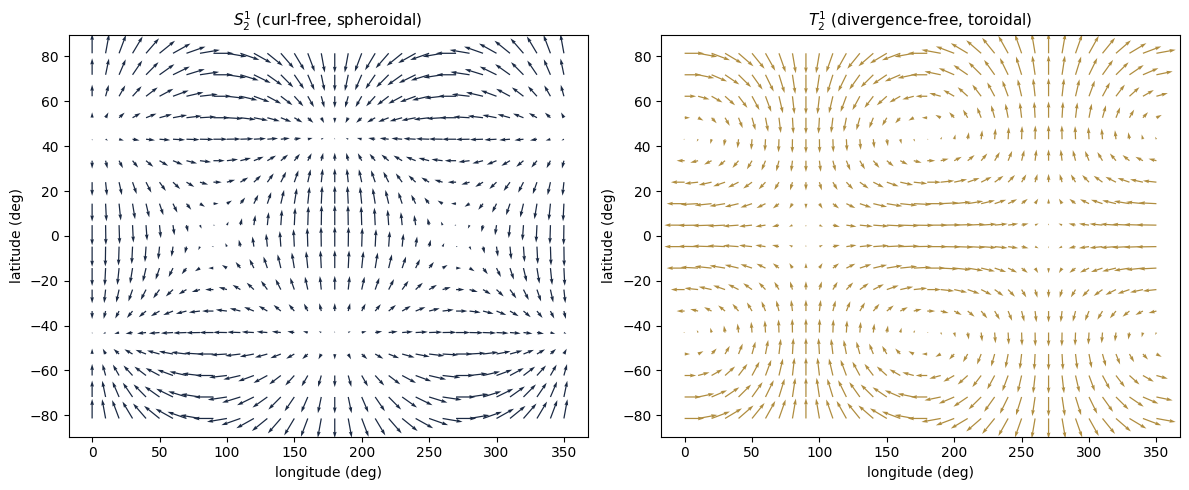

S flows from pole to pole along meridians where Y_2^1 changes fastest (curl-free);
T circulates around those same features at 90 degrees to S (divergence-free) -- as claimed in lecture.


In [5]:
l, m = 2, 1
theta_c = np.linspace(0.15, np.pi - 0.15, 18)
phi_c = np.linspace(0, 2 * np.pi, 36, endpoint=False)
THc, PHc = np.meshgrid(theta_c, phi_c, indexing="ij")
_, Sc, Tc = vector_harmonics(l, m, THc, PHc)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, field, title, color in zip(axs, [Sc, Tc], ["$S_2^1$ (curl-free, spheroidal)", "$T_2^1$ (divergence-free, toroidal)"], [NAVY, GOLD]):
    # plot on a longitude-latitude map; component[2] is phi (east), component[1] is theta (south)
    u = np.real(field[2])          # eastward component
    v = -np.real(field[1])         # northward component (south = +theta, so flip)
    ax.quiver(np.degrees(PHc), 90 - np.degrees(THc), u, v, color=color, scale=8)
    ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
    ax.set_title(title, fontsize=11)
plt.tight_layout(); plt.show()
print("S flows from pole to pole along meridians where Y_2^1 changes fastest (curl-free);")
print("T circulates around those same features at 90 degrees to S (divergence-free) -- as claimed in lecture.")

## Part 2 — Degeneracy and Splitting, Recovered by Fitting

Lecture stated that a spherically symmetric Earth gives a single degenerate peak at $_n\omega_l$ for all $m=-l..l$, while a slightly aspherical Earth splits that peak into $2l+1$ components. We build a synthetic split multiplet for $l=2$ with a *chosen* splitting parameter $\delta\omega$, add noise, and then recover $\delta\omega$ purely by fitting the synthetic spectrum -- the same exercise a seismologist runs on a real spectrum such as Figure 8.18's $_0S_2$ multiplet.

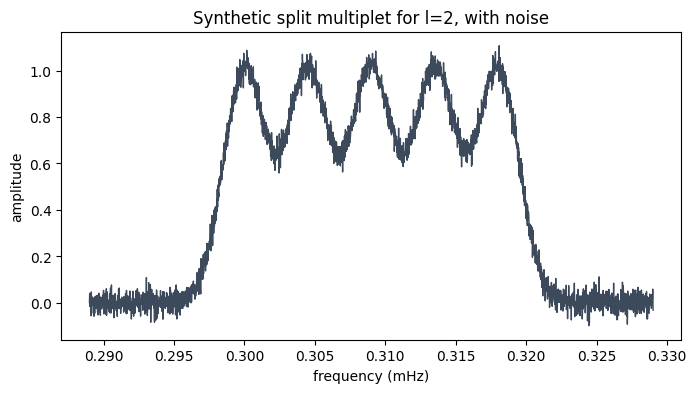

In [6]:
true_f0 = 0.309      # mHz, the 0S2 degenerate frequency used in lecture
true_delta = 0.0045   # mHz, the (chosen) splitting parameter -- unknown to the fit below
l = 2
width = 0.0015        # mHz, peak width

rng = np.random.default_rng(11)
f_axis = np.linspace(true_f0 - 0.02, true_f0 + 0.02, 3000)

def gaussian(f, f0, w, amp=1.0):
    return amp * np.exp(-0.5 * ((f - f0) / w) ** 2)

spectrum = np.zeros_like(f_axis)
for m in range(-l, l + 1):
    spectrum += gaussian(f_axis, true_f0 + m * true_delta, width)
spectrum += rng.normal(0, 0.03, size=f_axis.size)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(f_axis, spectrum, color=SLATE, lw=1.0)
ax.set_xlabel("frequency (mHz)"); ax.set_ylabel("amplitude")
ax.set_title("Synthetic split multiplet for l=2, with noise")
plt.show()

In [7]:
def five_peak_model(f, f0, delta, w, amp):
    out = np.zeros_like(f)
    for m in range(-l, l + 1):
        out += amp * np.exp(-0.5 * ((f - (f0 + m * delta)) / w) ** 2)
    return out

p0 = [true_f0 + 0.001, true_delta * 1.3, width * 1.2, 0.9]   # deliberately off-true starting guess
popt, pcov = curve_fit(five_peak_model, f_axis, spectrum, p0=p0)
f0_fit, delta_fit, w_fit, amp_fit = popt

print(f"True f0     = {true_f0:.4f} mHz   |  fitted f0     = {f0_fit:.4f} mHz")
print(f"True delta  = {true_delta:.4f} mHz   |  fitted delta  = {delta_fit:.4f} mHz")
assert abs(f0_fit - true_f0) < 2e-4
assert abs(delta_fit - true_delta) < 2e-4
print("\nThe splitting parameter is recovered from the noisy synthetic spectrum by fitting alone --")
print("exactly the inversion that turns an observed multiplet into a constraint on Earth's asphericity.")

True f0     = 0.3090 mHz   |  fitted f0     = 0.3090 mHz
True delta  = 0.0045 mHz   |  fitted delta  = 0.0045 mHz

The splitting parameter is recovered from the noisy synthetic spectrum by fitting alone --
exactly the inversion that turns an observed multiplet into a constraint on Earth's asphericity.


## Part 3 — Worked Checks: the Breathing and Football Modes

Lecture quoted periods for two named modes without deriving them: the breathing mode $_0S_0$ at about 20 minutes, and the football (rugby) mode $_0S_2$ at about 54 minutes. We convert both to frequency and confirm they match the peaks used to build the synthetic spectra above and in the deck.

In [8]:
named_modes = {"0S0": 20.0, "0S2": 54.0, "0S3": 28.0 * 60 / 60, "0S4": 25.8}
# (0S3, 0S4 periods are illustrative companions, not independently quoted in lecture)

for name, period_min in list(named_modes.items())[:2]:
    T_s = period_min * 60
    f_mHz = 1.0 / T_s * 1000
    print(f"{name}:  T = {period_min:.0f} min = {T_s:.0f} s  ->  f = {f_mHz:.3f} mHz")

f0_check = 1.0 / (20.0 * 60) * 1000
f2_check = 1.0 / (54.0 * 60) * 1000
assert abs(f0_check - 0.833) < 0.001
assert abs(f2_check - 0.309) < 0.001
print("\nBoth match the deck's worked results (0.833 mHz and 0.309 mHz) and the peak positions")
print("used to build the synthetic spectrum in Part 2.")

0S0:  T = 20 min = 1200 s  ->  f = 0.833 mHz
0S2:  T = 54 min = 3240 s  ->  f = 0.309 mHz

Both match the deck's worked results (0.833 mHz and 0.309 mHz) and the peak positions
used to build the synthetic spectrum in Part 2.


## Part 4 — Normal Modes and Synthetic Seismograms

Lecture's closing point was that normal modes provide a complete basis for synthetic seismograms. We reproduce the deck's demonstration -- summing several modes, each decaying at a rate set by the quality factor $Q$ -- and then explore how $Q$ controls the shape of the envelope, since attenuation is exactly what normal-mode observations are used to constrain.

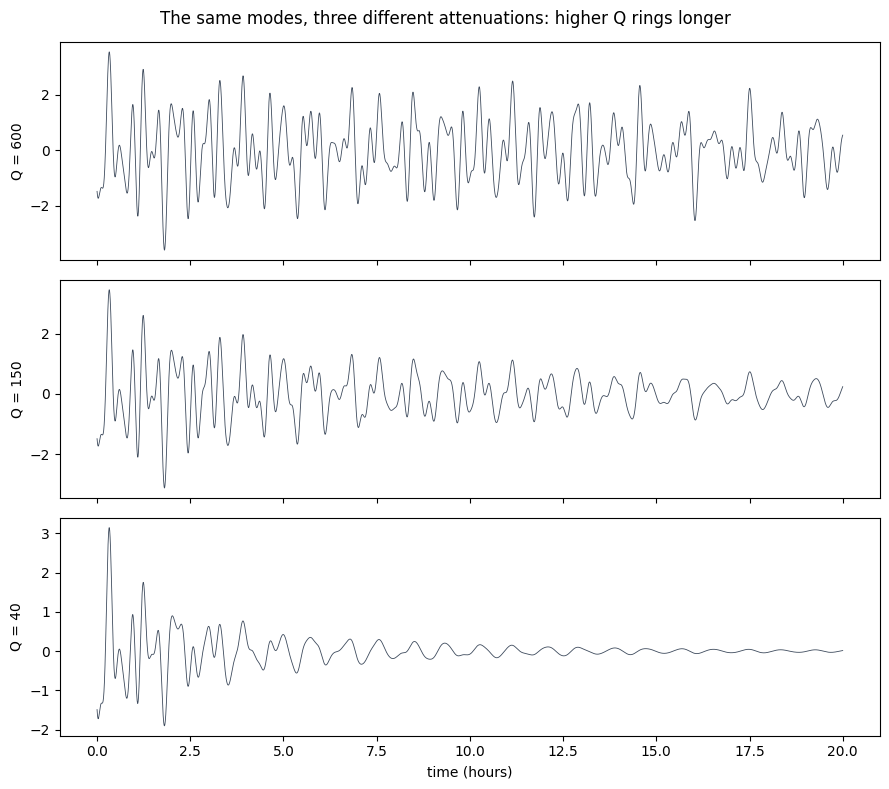

Low Q (strong attenuation) damps the ringing within a few hours; high Q lets the Earth
keep ringing for a day or more -- precisely how normal-mode decay rates constrain Q at long periods.


In [9]:
mode_freqs_mHz = {
    "0S0": 0.814, "0S2": 0.309, "0S3": 0.468, "0S4": 0.647,
    "0S5": 0.840, "0S6": 1.038, "0S7": 1.230,
}

def synth_seismogram(Q, t_max_hr=20, seed=3):
    t = np.linspace(0, t_max_hr * 3600, 8000)
    rng = np.random.default_rng(seed)
    out = np.zeros_like(t)
    for f_mhz in mode_freqs_mHz.values():
        omega = 2 * np.pi * f_mhz * 1e-3
        tau = Q / omega
        amp = rng.uniform(0.5, 1.0)
        phase = rng.uniform(0, 2 * np.pi)
        out += amp * np.exp(-t / tau) * np.cos(omega * t + phase)
    return t, out

fig, axs = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ax, Q in zip(axs, [600, 150, 40]):
    t, seis = synth_seismogram(Q)
    ax.plot(t / 3600, seis, color=SLATE, lw=0.6)
    ax.set_ylabel(f"Q = {Q}")
axs[-1].set_xlabel("time (hours)")
fig.suptitle("The same modes, three different attenuations: higher Q rings longer", fontsize=12)
plt.tight_layout(); plt.show()

print("Low Q (strong attenuation) damps the ringing within a few hours; high Q lets the Earth")
print("keep ringing for a day or more -- precisely how normal-mode decay rates constrain Q at long periods.")

## Summary

Displacement is a vector field on a sphere, so the Earth's normal modes are built from vector spherical harmonics R, S, and T rather than the scalar Y_l^m alone -- R and S combine for spheroidal motion, T alone gives toroidal motion, and all three are mutually orthogonal everywhere on the sphere. Spherical symmetry makes the eigenfrequency within each (n, l) group independent of m; real asphericity splits that single frequency into a multiplet whose spacing can be recovered directly from a noisy spectrum by fitting, exactly as it is from real seismograms. The whole machinery closes the loop back to Lecture 21: both the vibrating string and the ringing Earth are the same story -- a linear operator, a complete and orthogonal eigenbasis, and a simple weighted sum to represent any wave motion.